In [ ]:
import os
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image
from pathlib import Path
import time
from tqdm import tqdm # 加上进度条，让你看到进度

# ================= 配置 =================
DEVICE = torch.device("cuda") if torch.cuda.is_available() else torch.device("cpu")

# 图像尺寸 64x64 (非常小，适合快速验证)
IMAGE_SIZE = 64  
BATCH_SIZE = 128 # 加大 Batch Size，进一步减少循环次数
LEARNING_RATE = 0.001
NUM_EPOCHS = 15

# 路径
DATA_ROOT = "./dataset_manifold"
TRAIN_DIR = os.path.join(DATA_ROOT, "sim_train")
VAL_DIR = os.path.join(DATA_ROOT, "sim_val")
CLASS_NAMES = ["BPSK", "FSK2", "PSK8", "QAM16", "QAM64", "QPSK"]
NUM_CLASSES = len(CLASS_NAMES)

# ================= 1. 极速数据集 (内存全量加载) =================
class InMemoryDataset(Dataset):
    def __init__(self, root_dir):
        self.data = []
        self.labels = []
        
        # 定义预处理：直接转 Tensor 并 Resize
        self.transform = transforms.Compose([
            transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
            transforms.ToTensor()
        ])
        
        print(f"正在预加载数据至内存: {root_dir} ...")
        
        # 遍历读取
        if not os.path.exists(root_dir):
            print(f"Error: 路径不存在 {root_dir}")
            return

        total_files = sum([len(files) for r, d, files in os.walk(root_dir)])
        
        with tqdm(total=total_files, unit="img") as pbar:
            for cls_idx, cls_name in enumerate(CLASS_NAMES):
                cls_dir = Path(root_dir) / cls_name
                if not cls_dir.exists(): continue
                
                files = list(cls_dir.glob("*.png"))
                for p in files:
                    try:
                        # 立即读取并处理，存入 List
                        with Image.open(str(p)).convert("RGBA") as img:
                            tensor_img = self.transform(img)
                            self.data.append(tensor_img)
                            self.labels.append(cls_idx)
                    except Exception as e:
                        pass
                    pbar.update(1)
                    
        print(f"加载完成！共 {len(self.data)} 张图片。")

    def __len__(self):
        return len(self.data)
    
    def __getitem__(self, idx):
        # 直接从内存返回，无需磁盘IO，极快
        return self.data[idx], self.labels[idx]

# ================= 2. TinyCNN 模型 =================
class TinyCNN(nn.Module):
    def __init__(self, num_classes=6):
        super(TinyCNN, self).__init__()
        self.features = nn.Sequential(
            # Conv 1
            nn.Conv2d(4, 16, kernel_size=3, padding=1),
            nn.BatchNorm2d(16),
            nn.ReLU(),
            nn.MaxPool2d(2), # 64 -> 32
            # Conv 2
            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2), # 32 -> 16
            # Conv 3
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2)  # 16 -> 8
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 8 * 8, 128),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x

# ================= 3. 训练主程序 =================
def main():
    # 1. 预加载数据 (这步可能花 10-20秒，但是一劳永逸)
    print("Step 1: Loading Data into RAM...")
    train_ds = InMemoryDataset(TRAIN_DIR)
    val_ds = InMemoryDataset(VAL_DIR)
    
    if len(train_ds) == 0: return

    # num_workers=0 在 Windows 下通常最快，避免多进程启动开销
    train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=0)
    val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
    
    # 2. 初始化模型
    model = TinyCNN(NUM_CLASSES).to(DEVICE)
    optimizer = optim.Adam(model.parameters(), lr=LEARNING_RATE)
    criterion = nn.CrossEntropyLoss()
    
    print(f"\nStep 2: Start Training on {DEVICE}...")
    
    for epoch in range(NUM_EPOCHS):
        model.train()
        train_loss = 0
        correct = 0
        total = 0
        t0 = time.time()
        
        # 训练循环
        for imgs, labels in train_loader:
            imgs, labels = imgs.to(DEVICE), labels.to(DEVICE) # 数据已在内存，传输到 GPU 很快
            
            optimizer.zero_grad()
            outputs = model(imgs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            
            train_loss += loss.item()
            _, preds = outputs.max(1)
            correct += preds.eq(labels).sum().item()
            total += labels.size(0)
            
        train_acc = correct / total
        
        # 验证循环
        model.eval()
        val_correct = 0
        val_total = 0
        with torch.no_grad():
            for imgs, labels in val_loader:
                imgs, labels = imgs.to(DEVICE), labels.to(DEVICE)
                outputs = model(imgs)
                _, preds = outputs.max(1)
                val_correct += preds.eq(labels).sum().item()
                val_total += labels.size(0)
        
        val_acc = val_correct / val_total
        
        print(f"Epoch {epoch+1}/{NUM_EPOCHS} | "
              f"Time: {time.time()-t0:.2f}s | " # 注意看这个时间，应该非常短
              f"Train Acc: {train_acc:.4f} | "
              f"Val Acc: {val_acc:.4f}")

    print("\nTraining Finished.")

if __name__ == "__main__":
    main()

In [ ]:
import os
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image
from pathlib import Path
import time
from tqdm import tqdm
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix
import numpy as np

# ================= 配置 =================
DEVICE = torch.device("cuda") if torch.cuda.is_available() else torch.device("cpu")
IMAGE_SIZE = 64  
BATCH_SIZE = 128
LEARNING_RATE = 0.001
NUM_EPOCHS = 15

# 路径
DATA_ROOT = "./dataset_manifold"
TRAIN_DIR = os.path.join(DATA_ROOT, "sim_train")
VAL_DIR = os.path.join(DATA_ROOT, "sim_val")
REAL_TEST_DIR = os.path.join(DATA_ROOT, "real_test") # 真实数据路径

CLASS_NAMES = ["BPSK", "FSK2", "PSK8", "QAM16", "QAM64", "QPSK"]
NUM_CLASSES = len(CLASS_NAMES)

# ================= 1. 数据集定义 =================
class InMemoryDataset(Dataset):
    def __init__(self, root_dir, is_train=True):
        self.data = []
        self.labels = []
        self.transform = transforms.Compose([
            transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
            transforms.ToTensor()
        ])
        
        print(f"[{'Train/Val' if is_train else 'Real Test'}] 预加载数据: {root_dir}")
        if not os.path.exists(root_dir):
            print(f"Warning: 路径不存在 {root_dir}")
            return

        # 统计文件总数用于进度条
        files_list = []
        for cls_name in CLASS_NAMES:
            cls_dir = Path(root_dir) / cls_name
            if cls_dir.exists():
                files_list.extend([(p, cls_name) for p in cls_dir.glob("*.png")])
        
        # 预加载
        name_to_idx = {name: i for i, name in enumerate(CLASS_NAMES)}
        with tqdm(total=len(files_list), unit="img") as pbar:
            for p, cls_name in files_list:
                try:
                    with Image.open(str(p)).convert("RGBA") as img:
                        self.data.append(self.transform(img))
                        self.labels.append(name_to_idx[cls_name])
                except:
                    pass
                pbar.update(1)

    def __len__(self):
        return len(self.data)
    
    def __getitem__(self, idx):
        return self.data[idx], self.labels[idx]

# ================= 2. 模型定义 (TinyCNN) =================
class TinyCNN(nn.Module):
    def __init__(self, num_classes=6):
        super(TinyCNN, self).__init__()
        self.features = nn.Sequential(
            nn.Conv2d(4, 16, kernel_size=3, padding=1),
            nn.BatchNorm2d(16), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64), nn.ReLU(), nn.MaxPool2d(2)
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 8 * 8, 128),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        return self.classifier(self.features(x))

# ================= 3. 核心流程 =================
def main():
    # --- A. 准备数据 ---
    train_ds = InMemoryDataset(TRAIN_DIR, is_train=True)
    val_ds = InMemoryDataset(VAL_DIR, is_train=True)
    
    # 这里的关键：加载真实数据
    real_ds = InMemoryDataset(REAL_TEST_DIR, is_train=False)
    
    train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=0)
    val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
    
    if len(real_ds) > 0:
        real_loader = DataLoader(real_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
    else:
        print("\n错误：未检测到真实测试数据！请检查 dataset_manifold/real_test 目录。")
        real_loader = None

    # --- B. 训练 (或加载) ---
    model = TinyCNN(NUM_CLASSES).to(DEVICE)
    
    # 如果你刚才保存了模型，可以直接加载，节省 15秒
    if os.path.exists("tiny_cnn_manifold.pth"):
        print("\n发现已保存的模型，直接加载权重...")
        model.load_state_dict(torch.load("tiny_cnn_manifold.pth"))
    else:
        print("\n未找到模型，开始快速训练...")
        optimizer = optim.Adam(model.parameters(), lr=LEARNING_RATE)
        criterion = nn.CrossEntropyLoss()
        
        for epoch in range(NUM_EPOCHS):
            model.train()
            correct = 0
            total = 0
            for imgs, labels in train_loader:
                imgs, labels = imgs.to(DEVICE), labels.to(DEVICE)
                optimizer.zero_grad()
                outputs = model(imgs)
                loss = criterion(outputs, labels)
                loss.backward()
                optimizer.step()
                _, preds = outputs.max(1)
                correct += preds.eq(labels).sum().item()
                total += labels.size(0)
            print(f"Epoch {epoch+1}: Train Acc: {correct/total:.4f}")
        torch.save(model.state_dict(), "tiny_cnn_manifold.pth")

    # --- C. 真实数据评估 ---
    if real_loader:
        print("\n" + "="*40)
        print("     FINAL EXAM: REAL DATA TEST     ")
        print("="*40)
        
        model.eval()
        all_preds = []
        all_labels = []
        correct = 0
        total = 0
        
        with torch.no_grad():
            for imgs, labels in real_loader:
                imgs, labels = imgs.to(DEVICE), labels.to(DEVICE)
                outputs = model(imgs)
                _, preds = outputs.max(1)
                
                correct += preds.eq(labels).sum().item()
                total += labels.size(0)
                
                all_preds.extend(preds.cpu().numpy())
                all_labels.extend(labels.cpu().numpy())
        
        acc = correct / total
        print(f"\n>>> 真实数据准确率: {acc:.2%} ({correct}/{total}) <<<\n")
        
        # 绘制混淆矩阵
        cm = confusion_matrix(all_labels, all_preds)
        plt.figure(figsize=(8, 6))
        sns.heatmap(cm, annot=True, fmt='d', xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, cmap='Blues')
        plt.title(f"Real Data Confusion Matrix (TinyCNN)\nAccuracy: {acc:.2%}")
        plt.ylabel("True Label")
        plt.xlabel("Predicted Label")
        plt.show()

        # 打印详细分类报告
        from sklearn.metrics import classification_report
        print(classification_report(all_labels, all_preds, target_names=CLASS_NAMES))

if __name__ == "__main__":
    main()

In [ ]:
import os
import matplotlib.pyplot as plt
from PIL import Image
import random
from pathlib import Path

# 配置路径
DATA_ROOT = "./dataset_manifold"
SIM_DIR = os.path.join(DATA_ROOT, "sim_train")
REAL_DIR = os.path.join(DATA_ROOT, "real_test")
CLASS_NAMES = ["BPSK", "QAM16", "QAM64", "PSK8"] # 挑几个典型的看

def visualize_comparison():
    plt.figure(figsize=(12, 8))
    
    for i, cls_name in enumerate(CLASS_NAMES):
        # 获取模拟图
        sim_path = list(Path(SIM_DIR).joinpath(cls_name).glob("*.png"))
        if not sim_path: continue
        sim_img = Image.open(sim_path[0]).convert("RGBA")
        
        # 获取真实图
        real_path = list(Path(REAL_DIR).joinpath(cls_name).glob("*.png"))
        if not real_path: continue
        # 随机取一张，防止取到全黑的坏样本
        real_img = Image.open(random.choice(real_path)).convert("RGBA")
        
        # 绘图
        plt.subplot(len(CLASS_NAMES), 2, i*2 + 1)
        plt.imshow(sim_img)
        plt.title(f"Simulation: {cls_name}")
        plt.axis("off")
        
        plt.subplot(len(CLASS_NAMES), 2, i*2 + 2)
        plt.imshow(real_img)
        plt.title(f"Real Data: {cls_name}")
        plt.axis("off")
        
    plt.tight_layout()
    plt.show()

if __name__ == "__main__":
    visualize_comparison()

清理旧数据目录...
===== 1. 生成高保真模拟数据 =====
Generating BPSK...
Generating QPSK...
Generating PSK8...
Generating QAM16...


C:\Users\CPC-ML\AppData\Local\Temp\ipykernel_6384\3909954796.py:150: UserWarning: __floordiv__ is deprecated, and its behavior will change in a future version of pytorch. It currently rounds toward 0 (like the 'trunc' function NOT 'floor'). This results in incorrect rounding for negative values. To keep the current behavior, use torch.div(a, b, rounding_mode='trunc'), or for actual floor division, use torch.div(a, b, rounding_mode='floor').
  syms = ((idx // 4) * 2 - 3) + 1j*((idx % 4) * 2 - 3)


Generating QAM64...


C:\Users\CPC-ML\AppData\Local\Temp\ipykernel_6384\3909954796.py:153: UserWarning: __floordiv__ is deprecated, and its behavior will change in a future version of pytorch. It currently rounds toward 0 (like the 'trunc' function NOT 'floor'). This results in incorrect rounding for negative values. To keep the current behavior, use torch.div(a, b, rounding_mode='trunc'), or for actual floor division, use torch.div(a, b, rounding_mode='floor').
  syms = ((idx // 8) * 2 - 7) + 1j*((idx % 8) * 2 - 7)


Generating FSK2...

===== 2. 处理真实 IQ 文件 =====
Processing Real File: BPSK...
Processing Real File: QAM64...
Processing Real File: QAM16...
Processing Real File: PSK8...
Processing Real File: QPSK...
Processing Real File: FSK2...
Loading ./dataset_manifold_v2\sim_train into RAM...


100%|██████████| 3812/3812 [00:12<00:00, 307.41img/s]


Loading ./dataset_manifold_v2\sim_val into RAM...


100%|██████████| 988/988 [00:03<00:00, 306.70img/s]


Loading ./dataset_manifold_v2\real_test into RAM...


100%|██████████| 29292/29292 [01:42<00:00, 285.70img/s]



===== 开始训练 TinyCNN (60 Epochs) =====
Epoch 1: Train Acc: 0.3618 | Sim Val Acc: 0.3239
Epoch 2: Train Acc: 0.5669 | Sim Val Acc: 0.6832
Epoch 3: Train Acc: 0.6548 | Sim Val Acc: 0.7429
Epoch 4: Train Acc: 0.7038 | Sim Val Acc: 0.6872
Epoch 5: Train Acc: 0.7209 | Sim Val Acc: 0.7045
Epoch 6: Train Acc: 0.7358 | Sim Val Acc: 0.6974
Epoch 7: Train Acc: 0.7385 | Sim Val Acc: 0.7540
Epoch 8: Train Acc: 0.7657 | Sim Val Acc: 0.7561
Epoch 9: Train Acc: 0.7524 | Sim Val Acc: 0.7804
Epoch 10: Train Acc: 0.7891 | Sim Val Acc: 0.7874
Epoch 11: Train Acc: 0.8040 | Sim Val Acc: 0.7824
Epoch 12: Train Acc: 0.8158 | Sim Val Acc: 0.7976
Epoch 13: Train Acc: 0.8206 | Sim Val Acc: 0.7591
Epoch 14: Train Acc: 0.7972 | Sim Val Acc: 0.8026
Epoch 15: Train Acc: 0.8143 | Sim Val Acc: 0.7642
Epoch 16: Train Acc: 0.8182 | Sim Val Acc: 0.7804
Epoch 17: Train Acc: 0.8256 | Sim Val Acc: 0.8036
Epoch 18: Train Acc: 0.8363 | Sim Val Acc: 0.7854
Epoch 19: Train Acc: 0.8636 | Sim Val Acc: 0.7895
Epoch 20: Train Acc: 

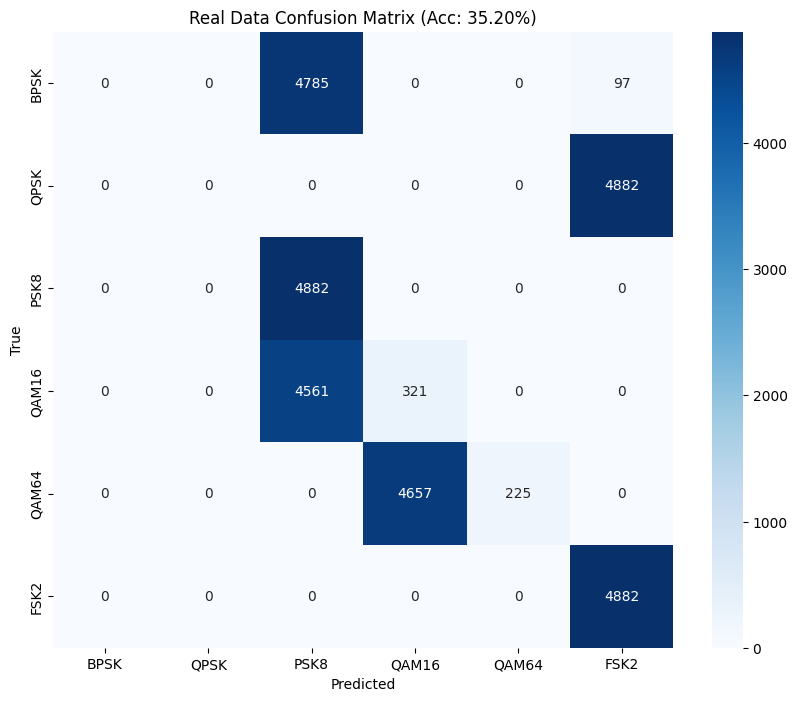

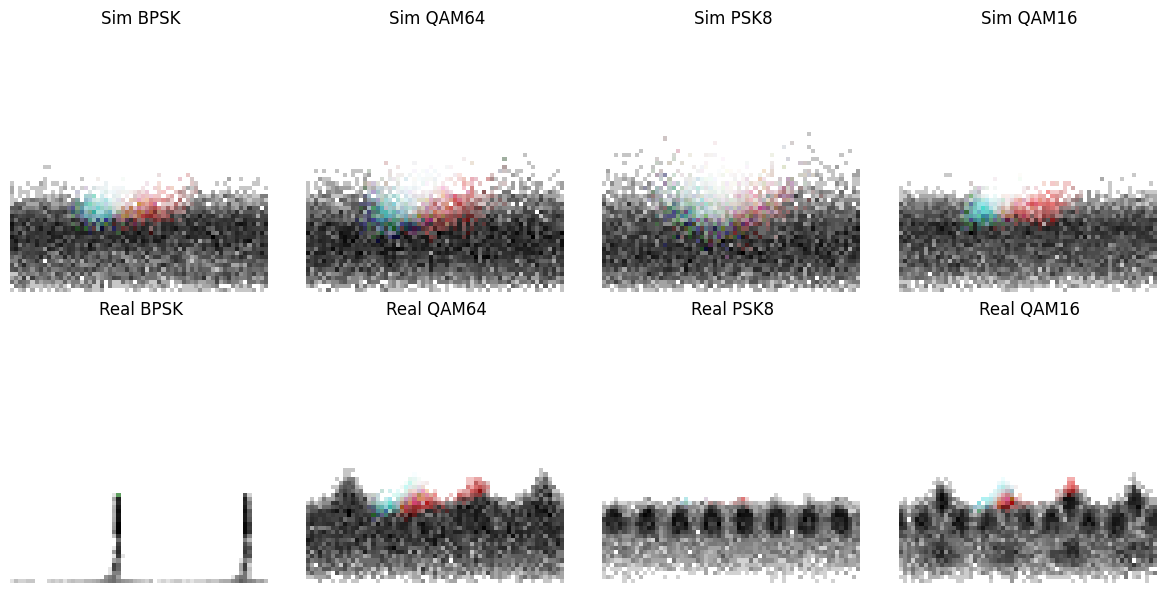

In [3]:
import os
import shutil
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report
from tqdm import tqdm
import random

# ================= 0. 全局配置 =================
DEVICE = torch.device("cuda") if torch.cuda.is_available() else torch.device("cpu")

# 核心参数
SAMPLES_PER_IMAGE = 10240   # 长曝光
IMAGE_SIZE = 64             # 64x64 分辨率
BATCH_SIZE = 128
LEARNING_RATE = 0.001
NUM_EPOCHS = 60

# 数据量配置
TOTAL_SIM_SAMPLES_PER_CLASS = 800
TRAIN_VAL_RATIO = 0.8

# 路径配置
DATASET_ROOT = "./dataset_manifold_v2"
SIM_TRAIN_DIR = os.path.join(DATASET_ROOT, "sim_train")
SIM_VAL_DIR = os.path.join(DATASET_ROOT, "sim_val")
REAL_TEST_DIR = os.path.join(DATASET_ROOT, "real_test")

# 真实数据映射
FILE_MAPPING = {
    "E:/Project/AMR-Benchmark/BPSK-03-24-25-10h52m32s937.iq": "BPSK",
    "E:/Project/AMR-Benchmark/QAM64-03-24-25-10h51m51s805.iq": "QAM64",
    "E:/Project/AMR-Benchmark/QAM16-03-24-25-10h52m09s762.iq": "QAM16",
    "E:/Project/AMR-Benchmark/PSK8-03-24-25-10h54m48s14.iq": "PSK8",
    "E:/Project/AMR-Benchmark/QPSK-03-24-25-10h53m20s46.iq": "QPSK",
    "E:/Project/AMR-Benchmark/FSK2DEV625KHZ-03-24-25-11h08m50s462.iq": "FSK2"
}

CLASS_NAMES = ["BPSK", "QPSK", "PSK8", "QAM16", "QAM64", "FSK2"]
NUM_CLASSES = len(CLASS_NAMES)


# ================= 1. 核心数学工具 =================

def fast_hist2d(x, y, bins=64, range_bounds=((-1, 1), (-1, 1))):
    x_min, x_max = range_bounds[0]
    y_min, y_max = range_bounds[1]
    x = torch.clamp(x, x_min, x_max)
    y = torch.clamp(y, y_min, y_max)
    
    x_idx = ((x - x_min) / (x_max - x_min) * (bins - 1)).long()
    y_idx = ((y - y_min) / (y_max - y_min) * (bins - 1)).long()
    
    flat_idx = y_idx * bins + x_idx
    hist = torch.bincount(flat_idx, minlength=bins*bins)
    return hist.view(bins, bins).float()

def generate_manifold_heatmap(iq_complex_data, img_size=64):
    if iq_complex_data.dim() == 1:
        iq_complex_data = iq_complex_data.unsqueeze(0)
    
    iq_data = iq_complex_data.squeeze()
    if iq_data.numel() < 100: return torch.zeros(4, img_size, img_size)

    # 1. 鲁棒归一化
    # 注意：这里必须要保证输入是 Complex 类型，否则 .imag 会报错
    scale = torch.sqrt(torch.mean(iq_data.real**2 + iq_data.imag**2)) + 1e-9
    norm_iq = iq_data / (3.0 * scale)
    
    real = norm_iq.real
    imag = norm_iq.imag
    
    real_curr, real_prev = real[1:], real[:-1]
    imag_curr, imag_prev = imag[1:], imag[:-1]
    
    phase = torch.angle(norm_iq) / np.pi
    mag = torch.abs(norm_iq)
    
    bins = img_size
    hist_r = fast_hist2d(real, imag, bins=bins, range_bounds=((-1.2, 1.2), (-1.2, 1.2)))
    hist_g = fast_hist2d(real_curr, real_prev, bins=bins, range_bounds=((-1.2, 1.2), (-1.2, 1.2)))
    hist_b = fast_hist2d(imag_curr, imag_prev, bins=bins, range_bounds=((-1.2, 1.2), (-1.2, 1.2)))
    hist_a = fast_hist2d(phase, mag, bins=bins, range_bounds=((-1.0, 1.0), (0.0, 1.5)))
    
    def process(h):
        h = torch.log1p(h)
        return (h - h.min()) / (h.max() - h.min() + 1e-8)
        
    img_tensor = torch.stack([process(hist_r), process(hist_g), process(hist_b), process(hist_a)], dim=0)
    return torch.flip(img_tensor, [1]) 

def save_tensor_as_rgba(tensor, path):
    tensor = tensor.detach().cpu()
    arr = tensor.permute(1, 2, 0).numpy()
    arr = (arr * 255).astype(np.uint8)
    Image.fromarray(arr, mode='RGBA').save(path)


# ================= 2. 高保真信号生成 =================

def generate_rrc_filter(N_taps, beta, sps):
    t = torch.arange(-(N_taps - 1) // 2, (N_taps - 1) // 2 + 1, dtype=torch.float32) / sps
    mid_idx = (N_taps - 1) // 2
    t[mid_idx] = 1e-8
    num = torch.sin(np.pi * t * (1 - beta)) + 4 * beta * t * torch.cos(np.pi * t * (1 + beta))
    den = np.pi * t * (1 - (4 * beta * t)**2)
    coeffs = num / den
    coeffs[mid_idx] = 1 - beta + (4 * beta / np.pi)
    return coeffs / torch.sqrt(torch.sum(coeffs**2))

def apply_channel_effects(sig, snr_db):
    N = len(sig)
    freq_offset = np.random.uniform(-400, 400)
    t = torch.arange(N, dtype=torch.float32) / 80e3
    rotation = torch.exp(1j * 2 * np.pi * freq_offset * t)
    sig = sig * rotation
    
    phase_jitter = torch.randn(N) * 0.02
    sig = sig * torch.exp(1j * phase_jitter)
    
    sig_power = torch.mean(torch.abs(sig)**2)
    noise_power = sig_power / (10**(snr_db/10.0))
    noise = (torch.randn_like(sig) + 1j*torch.randn_like(sig)) * torch.sqrt(noise_power/2)
    return sig + noise

def generate_sim_signal(mod_type, N, snr_db):
    Fs, Rs = 80e3, 20e3
    sps = int(Fs / Rs)
    num_symbols = int(N / sps) + 50
    
    if mod_type == "BPSK":
        syms = 2*torch.randint(0, 2, (num_symbols,)) - 1 + 0j
    elif mod_type == "QPSK":
        phase = np.pi/4 + torch.randint(0, 4, (num_symbols,)) * np.pi/2
        syms = torch.exp(1j * phase)
    elif mod_type == "PSK8":
        phase = torch.randint(0, 8, (num_symbols,)) * 2*np.pi/8
        syms = torch.exp(1j * phase)
    elif mod_type == "QAM16":
        idx = torch.randint(0, 16, (num_symbols,))
        syms = ((idx // 4) * 2 - 3) + 1j*((idx % 4) * 2 - 3)
    elif mod_type == "QAM64":
        idx = torch.randint(0, 64, (num_symbols,))
        syms = ((idx // 8) * 2 - 7) + 1j*((idx % 8) * 2 - 7)
    elif mod_type == "FSK2":
        bits = torch.randint(0, 2, (N + 100,))
        freqs = (bits * 2 - 1) * (Rs/4)
        phase = 2 * np.pi * torch.cumsum(freqs/Fs, dim=0)
        sig = torch.exp(1j * phase)[:N]
        return apply_channel_effects(sig, snr_db)

    upsampled = torch.zeros(num_symbols * sps, dtype=torch.complex64)
    upsampled[::sps] = syms
    taps = 10 * sps + 1
    h = generate_rrc_filter(taps, 0.35, sps)
    real = F.conv1d(upsampled.real.view(1,1,-1), h.view(1,1,-1), padding=taps//2)
    imag = F.conv1d(upsampled.imag.view(1,1,-1), h.view(1,1,-1), padding=taps//2)
    sig = (real + 1j*imag).squeeze()
    
    if len(sig) > N: sig = sig[:N]
    else: sig = F.pad(sig, (0, N - len(sig)))
    return apply_channel_effects(sig, snr_db)


# ================= 3. 数据生成管道 =================

def generate_datasets():
    if os.path.exists(DATASET_ROOT):
        print("清理旧数据目录...")
        shutil.rmtree(DATASET_ROOT)
    
    print("===== 1. 生成高保真模拟数据 =====")
    for cls_name in CLASS_NAMES:
        os.makedirs(os.path.join(SIM_TRAIN_DIR, cls_name), exist_ok=True)
        os.makedirs(os.path.join(SIM_VAL_DIR, cls_name), exist_ok=True)
        print(f"Generating {cls_name}...")
        for i in range(TOTAL_SIM_SAMPLES_PER_CLASS):
            target_dir = SIM_TRAIN_DIR if np.random.rand() < TRAIN_VAL_RATIO else SIM_VAL_DIR
            target_dir = os.path.join(target_dir, cls_name)
            snr = np.random.uniform(-5, 25)
            sig = generate_sim_signal(cls_name, SAMPLES_PER_IMAGE, snr)
            heatmap = generate_manifold_heatmap(sig.to(DEVICE), IMAGE_SIZE)
            save_tensor_as_rgba(heatmap, os.path.join(target_dir, f"{cls_name}_{i:04d}_{snr:.1f}.png"))

    print("\n===== 2. 处理真实 IQ 文件 =====")
    for file_path, label in FILE_MAPPING.items():
        if not os.path.exists(file_path): 
            print(f"Skip missing file: {file_path}")
            continue
            
        print(f"Processing Real File: {label}...")
        save_dir = os.path.join(REAL_TEST_DIR, label)
        os.makedirs(save_dir, exist_ok=True)
        
        # [FIXED HERE] 读取 int16 二进制 -> Complex64
        raw = np.fromfile(file_path, dtype=np.int16)
        if len(raw) % 2 != 0: raw = raw[:-1]
        
        # 修正类型转换顺序：先转 float32 保持精度，再组合成 complex
        I = raw[::2].astype(np.float32)
        Q = raw[1::2].astype(np.float32)
        iq_complex = (I + 1j * Q).astype(np.complex64) / 32767.0
        
        num_slices = len(iq_complex) // SAMPLES_PER_IMAGE
        for i in range(num_slices):
            chunk = iq_complex[i*SAMPLES_PER_IMAGE : (i+1)*SAMPLES_PER_IMAGE]
            chunk_tensor = torch.from_numpy(chunk).to(DEVICE)
            heatmap = generate_manifold_heatmap(chunk_tensor, IMAGE_SIZE)
            save_tensor_as_rgba(heatmap, os.path.join(save_dir, f"real_{i:04d}.png"))


# ================= 4. 模型与训练 =================

class TinyCNN(nn.Module):
    def __init__(self, num_classes):
        super(TinyCNN, self).__init__()
        self.features = nn.Sequential(
            nn.Conv2d(4, 16, 3, padding=1), nn.BatchNorm2d(16), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(16, 32, 3, padding=1), nn.BatchNorm2d(32), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1), nn.BatchNorm2d(64), nn.ReLU(), nn.MaxPool2d(2)
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64*8*8, 128), nn.ReLU(), nn.Dropout(0.5),
            nn.Linear(128, num_classes)
        )
    def forward(self, x): return self.classifier(self.features(x))

class InMemoryDataset(Dataset):
    def __init__(self, root_dir):
        self.data, self.labels = [], []
        self.transform = transforms.Compose([transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)), transforms.ToTensor()])
        if not os.path.exists(root_dir): return
        print(f"Loading {root_dir} into RAM...")
        files = []
        for cls_name in CLASS_NAMES:
            d = Path(root_dir) / cls_name
            if d.exists(): files.extend([(p, CLASS_NAMES.index(cls_name)) for p in d.glob("*.png")])
        with tqdm(total=len(files), unit="img") as pbar:
            for p, label in files:
                try:
                    with Image.open(str(p)).convert("RGBA") as img:
                        self.data.append(self.transform(img))
                        self.labels.append(label)
                except: pass
                pbar.update(1)
    def __len__(self): return len(self.data)
    def __getitem__(self, idx): return self.data[idx], self.labels[idx]

def train_and_eval():
    train_ds = InMemoryDataset(SIM_TRAIN_DIR)
    val_ds = InMemoryDataset(SIM_VAL_DIR)
    real_ds = InMemoryDataset(REAL_TEST_DIR)
    
    train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=0)
    val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
    
    model = TinyCNN(NUM_CLASSES).to(DEVICE)
    optimizer = optim.Adam(model.parameters(), lr=LEARNING_RATE)
    criterion = nn.CrossEntropyLoss()
    
    print(f"\n===== 开始训练 TinyCNN ({NUM_EPOCHS} Epochs) =====")
    for epoch in range(NUM_EPOCHS):
        model.train()
        correct, total = 0, 0
        for imgs, labels in train_loader:
            imgs, labels = imgs.to(DEVICE), labels.to(DEVICE)
            optimizer.zero_grad()
            outputs = model(imgs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            _, preds = outputs.max(1)
            correct += preds.eq(labels).sum().item()
            total += labels.size(0)
            
        model.eval()
        val_correct, val_total = 0, 0
        with torch.no_grad():
            for imgs, labels in val_loader:
                imgs, labels = imgs.to(DEVICE), labels.to(DEVICE)
                outputs = model(imgs)
                _, preds = outputs.max(1)
                val_correct += preds.eq(labels).sum().item()
                val_total += labels.size(0)
        print(f"Epoch {epoch+1}: Train Acc: {correct/total:.4f} | Sim Val Acc: {val_correct/val_total:.4f}")

    if len(real_ds) > 0:
        real_loader = DataLoader(real_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
        print("\n===== 真实数据终极测试 =====")
        model.eval()
        all_preds, all_labels = [], []
        correct, total = 0, 0
        with torch.no_grad():
            for imgs, labels in real_loader:
                imgs, labels = imgs.to(DEVICE), labels.to(DEVICE)
                outputs = model(imgs)
                _, preds = outputs.max(1)
                correct += preds.eq(labels).sum().item()
                total += labels.size(0)
                all_preds.extend(preds.cpu().numpy())
                all_labels.extend(labels.cpu().numpy())
        acc = correct / total
        print(f">>> 真实数据准确率: {acc:.2%} ({correct}/{total}) <<<")
        cm = confusion_matrix(all_labels, all_preds)
        plt.figure(figsize=(10, 8))
        sns.heatmap(cm, annot=True, fmt='d', xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, cmap='Blues')
        plt.title(f"Real Data Confusion Matrix (Acc: {acc:.2%})")
        plt.xlabel("Predicted"); plt.ylabel("True"); plt.show()

def visualize_sim_vs_real():
    plt.figure(figsize=(12, 6))
    cols = 4
    for i, cls in enumerate(["BPSK", "QAM64", "PSK8", "QAM16"]):
        sim_files = list(Path(SIM_TRAIN_DIR).joinpath(cls).glob("*.png"))
        real_files = list(Path(REAL_TEST_DIR).joinpath(cls).glob("*.png"))
        if sim_files:
            plt.subplot(2, cols, i+1)
            plt.imshow(Image.open(sim_files[0]))
            plt.title(f"Sim {cls}"); plt.axis('off')
        if real_files:
            plt.subplot(2, cols, i+1+cols)
            plt.imshow(Image.open(random.choice(real_files)))
            plt.title(f"Real {cls}"); plt.axis('off')
    plt.tight_layout(); plt.show()

if __name__ == "__main__":
    generate_datasets()
    train_and_eval()
    visualize_sim_vs_real()

===== 1. 生成高保真模拟数据 (V3: Clean RF) =====
Generating BPSK...
Generating QPSK...
Generating PSK8...
Generating QAM16...


C:\Users\CPC-ML\AppData\Local\Temp\ipykernel_6384\4130768939.py:178: UserWarning: __floordiv__ is deprecated, and its behavior will change in a future version of pytorch. It currently rounds toward 0 (like the 'trunc' function NOT 'floor'). This results in incorrect rounding for negative values. To keep the current behavior, use torch.div(a, b, rounding_mode='trunc'), or for actual floor division, use torch.div(a, b, rounding_mode='floor').
  syms = ((idx // 4) * 2 - 3) + 1j*((idx % 4) * 2 - 3)


Generating QAM64...


C:\Users\CPC-ML\AppData\Local\Temp\ipykernel_6384\4130768939.py:181: UserWarning: __floordiv__ is deprecated, and its behavior will change in a future version of pytorch. It currently rounds toward 0 (like the 'trunc' function NOT 'floor'). This results in incorrect rounding for negative values. To keep the current behavior, use torch.div(a, b, rounding_mode='trunc'), or for actual floor division, use torch.div(a, b, rounding_mode='floor').
  syms = ((idx // 8) * 2 - 7) + 1j*((idx % 8) * 2 - 7)


Generating FSK2...

===== 2. 处理真实 IQ 文件 =====
Processing Real File: BPSK...
Processing Real File: QAM64...
Processing Real File: QAM16...
Processing Real File: PSK8...
Processing Real File: QPSK...
Processing Real File: FSK2...
Loading ./dataset_manifold_v3\sim_train into RAM...


100%|██████████| 3817/3817 [00:13<00:00, 293.02img/s]


Loading ./dataset_manifold_v3\sim_val into RAM...


100%|██████████| 983/983 [00:03<00:00, 283.07img/s]


Loading ./dataset_manifold_v3\real_test into RAM...


100%|██████████| 29292/29292 [01:41<00:00, 287.50img/s]



===== 开始训练 TinyCNN (15 Epochs) =====
Epoch 1: Train Acc: 0.5368 | Sim Val Acc: 0.3174
Epoch 2: Train Acc: 0.8300 | Sim Val Acc: 0.9430
Epoch 3: Train Acc: 0.9287 | Sim Val Acc: 0.9746
Epoch 4: Train Acc: 0.9513 | Sim Val Acc: 0.9817
Epoch 5: Train Acc: 0.9680 | Sim Val Acc: 0.9868
Epoch 6: Train Acc: 0.9806 | Sim Val Acc: 0.9908
Epoch 7: Train Acc: 0.9835 | Sim Val Acc: 0.9929
Epoch 8: Train Acc: 0.9817 | Sim Val Acc: 0.9949
Epoch 9: Train Acc: 0.9866 | Sim Val Acc: 0.9949
Epoch 10: Train Acc: 0.9893 | Sim Val Acc: 0.9969
Epoch 11: Train Acc: 0.9929 | Sim Val Acc: 0.9898
Epoch 12: Train Acc: 0.9908 | Sim Val Acc: 0.9980
Epoch 13: Train Acc: 0.9903 | Sim Val Acc: 0.9980
Epoch 14: Train Acc: 0.9919 | Sim Val Acc: 1.0000
Epoch 15: Train Acc: 0.9940 | Sim Val Acc: 0.9990

===== 真实数据终极测试 =====
>>> 真实数据准确率: 99.41% (29118/29292) <<<


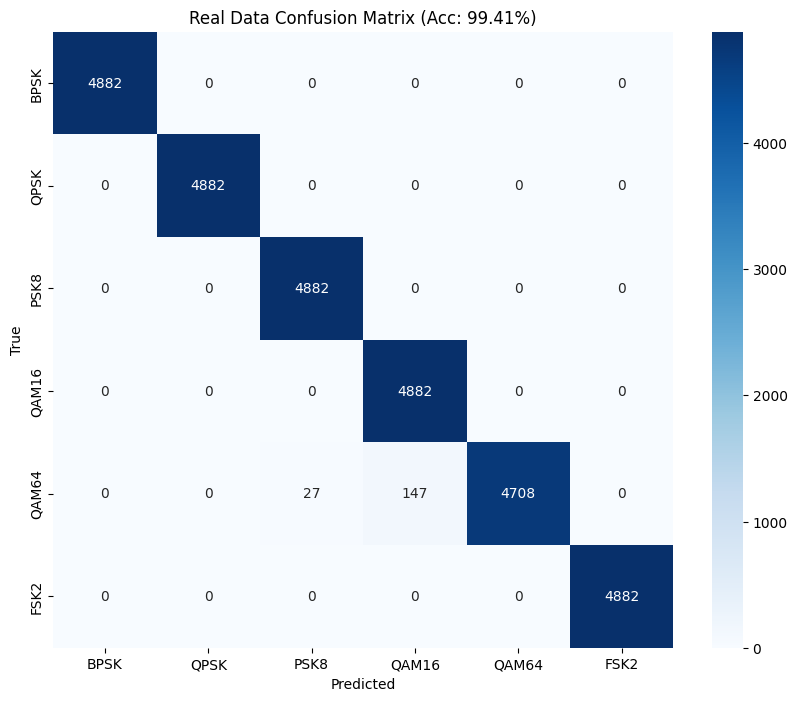

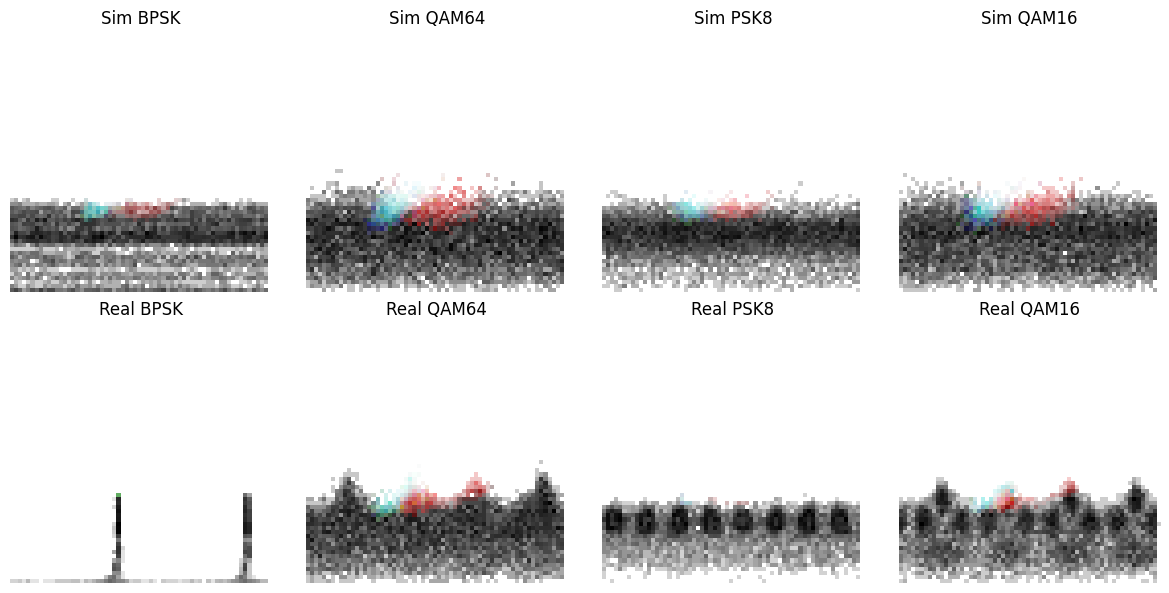

In [4]:
import os
import shutil
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix
from tqdm import tqdm
import random

# ================= 0. 全局配置 =================
DEVICE = torch.device("cuda") if torch.cuda.is_available() else torch.device("cpu")

# 核心参数
SAMPLES_PER_IMAGE = 10240   # 长曝光，捕捉轨迹
IMAGE_SIZE = 64             # 64x64 足够识别几何特征
BATCH_SIZE = 128
LEARNING_RATE = 0.001
NUM_EPOCHS = 15             # 15轮足够收敛

# 数据量配置
TOTAL_SIM_SAMPLES_PER_CLASS = 800
TRAIN_VAL_RATIO = 0.8

# 路径配置
DATASET_ROOT = "./dataset_manifold_v3" # 使用 v3 版本
SIM_TRAIN_DIR = os.path.join(DATASET_ROOT, "sim_train")
SIM_VAL_DIR = os.path.join(DATASET_ROOT, "sim_val")
REAL_TEST_DIR = os.path.join(DATASET_ROOT, "real_test")

# 真实数据映射 (请确保路径正确)
FILE_MAPPING = {
    "E:/Project/AMR-Benchmark/BPSK-03-24-25-10h52m32s937.iq": "BPSK",
    "E:/Project/AMR-Benchmark/QAM64-03-24-25-10h51m51s805.iq": "QAM64",
    "E:/Project/AMR-Benchmark/QAM16-03-24-25-10h52m09s762.iq": "QAM16",
    "E:/Project/AMR-Benchmark/PSK8-03-24-25-10h54m48s14.iq": "PSK8",
    "E:/Project/AMR-Benchmark/QPSK-03-24-25-10h53m20s46.iq": "QPSK",
    "E:/Project/AMR-Benchmark/FSK2DEV625KHZ-03-24-25-11h08m50s462.iq": "FSK2"
}

CLASS_NAMES = ["BPSK", "QPSK", "PSK8", "QAM16", "QAM64", "FSK2"]
NUM_CLASSES = len(CLASS_NAMES)


# ================= 1. 核心数学工具 (GPU加速) =================

def fast_hist2d(x, y, bins=64, range_bounds=((-1, 1), (-1, 1))):
    x_min, x_max = range_bounds[0]
    y_min, y_max = range_bounds[1]
    x = torch.clamp(x, x_min, x_max)
    y = torch.clamp(y, y_min, y_max)
    
    x_idx = ((x - x_min) / (x_max - x_min) * (bins - 1)).long()
    y_idx = ((y - y_min) / (y_max - y_min) * (bins - 1)).long()
    
    flat_idx = y_idx * bins + x_idx
    hist = torch.bincount(flat_idx, minlength=bins*bins)
    return hist.view(bins, bins).float()

def generate_manifold_heatmap(iq_complex_data, img_size=64):
    if iq_complex_data.dim() == 1:
        iq_complex_data = iq_complex_data.unsqueeze(0)
    
    iq_data = iq_complex_data.squeeze()
    if iq_data.numel() < 100: return torch.zeros(4, img_size, img_size)

    # 1. 鲁棒归一化
    # 真实数据的幅度变化较大，使用统计值归一化
    scale = torch.sqrt(torch.mean(iq_data.real**2 + iq_data.imag**2)) + 1e-9
    norm_iq = iq_data / (3.0 * scale)
    
    real = norm_iq.real
    imag = norm_iq.imag
    
    # 2. 构造相空间延迟坐标
    real_curr, real_prev = real[1:], real[:-1]
    imag_curr, imag_prev = imag[1:], imag[:-1]
    
    # 3. 构造极坐标
    phase = torch.angle(norm_iq) / np.pi 
    mag = torch.abs(norm_iq)
    
    # 4. 生成直方图
    bins = img_size
    # R: Constellation
    hist_r = fast_hist2d(real, imag, bins=bins, range_bounds=((-1.2, 1.2), (-1.2, 1.2)))
    # G: Real Trajectory
    hist_g = fast_hist2d(real_curr, real_prev, bins=bins, range_bounds=((-1.2, 1.2), (-1.2, 1.2)))
    # B: Imag Trajectory
    hist_b = fast_hist2d(imag_curr, imag_prev, bins=bins, range_bounds=((-1.2, 1.2), (-1.2, 1.2)))
    # A: Polar (Phase vs Mag) - 这一层对 BPSK 识别至关重要 (两根柱子)
    hist_a = fast_hist2d(phase, mag, bins=bins, range_bounds=((-1.0, 1.0), (0.0, 1.5)))
    
    def process(h):
        h = torch.log1p(h)
        return (h - h.min()) / (h.max() - h.min() + 1e-8)
        
    img_tensor = torch.stack([process(hist_r), process(hist_g), process(hist_b), process(hist_a)], dim=0)
    return torch.flip(img_tensor, [1]) 

def save_tensor_as_rgba(tensor, path):
    tensor = tensor.detach().cpu()
    arr = tensor.permute(1, 2, 0).numpy()
    arr = (arr * 255).astype(np.uint8)
    Image.fromarray(arr, mode='RGBA').save(path)


# ================= 2. 高保真信号生成 (Precision RF) =================
# 修正重点：大幅降低相位噪声和频偏，对齐真实数据的“干净”特征

def generate_rrc_filter(N_taps, beta, sps):
    t = torch.arange(-(N_taps - 1) // 2, (N_taps - 1) // 2 + 1, dtype=torch.float32) / sps
    mid_idx = (N_taps - 1) // 2
    t[mid_idx] = 1e-8
    num = torch.sin(np.pi * t * (1 - beta)) + 4 * beta * t * torch.cos(np.pi * t * (1 + beta))
    den = np.pi * t * (1 - (4 * beta * t)**2)
    coeffs = num / den
    coeffs[mid_idx] = 1 - beta + (4 * beta / np.pi)
    return coeffs / torch.sqrt(torch.sum(coeffs**2))

def apply_channel_effects(sig, snr_db):
    N = len(sig)
    
    # 1. 载波频偏 (CFO) - 极慢速漂移
    # 真实数据 BPSK 是柱子而非圆环，说明频偏被锁定了或很小
    freq_offset = np.random.uniform(-50, 50) 
    t = torch.arange(N, dtype=torch.float32) / 80e3
    
    # 初始相位随机，但旋转很慢
    phase_offset = np.random.uniform(0, 2*np.pi)
    rotation = torch.exp(1j * (2 * np.pi * freq_offset * t + phase_offset))
    sig = sig * rotation
    
    # 2. 相位抖动 (Phase Noise) - 大幅降低
    # 真实数据点很锐利，不能加太多抖动
    phase_jitter = torch.randn(N) * 0.005 
    sig = sig * torch.exp(1j * phase_jitter)
    
    # 3. IQ 不平衡
    g_imbalance = np.random.uniform(0.98, 1.02)
    p_imbalance = np.random.uniform(-1, 1) * np.pi/180
    real = sig.real * g_imbalance
    imag = sig.imag * np.cos(p_imbalance) - sig.real * np.sin(p_imbalance)
    sig = torch.complex(real, imag)
    
    # 4. 高斯白噪声 (AWGN)
    # 提高信噪比下限，真实数据看起来很清晰
    sig_power = torch.mean(torch.abs(sig)**2)
    # 设定信噪比范围：10dB ~ 30dB
    real_snr = snr_db + 10 
    noise_power = sig_power / (10**(real_snr/10.0))
    noise = (torch.randn_like(sig) + 1j*torch.randn_like(sig)) * torch.sqrt(noise_power/2)
    
    return sig + noise

def generate_sim_signal(mod_type, N, snr_db):
    Fs, Rs = 80e3, 20e3
    sps = int(Fs / Rs)
    num_symbols = int(N / sps) + 50
    
    if mod_type == "BPSK":
        syms = 2*torch.randint(0, 2, (num_symbols,)) - 1 + 0j
    elif mod_type == "QPSK":
        phase = np.pi/4 + torch.randint(0, 4, (num_symbols,)) * np.pi/2
        syms = torch.exp(1j * phase)
    elif mod_type == "PSK8":
        phase = torch.randint(0, 8, (num_symbols,)) * 2*np.pi/8
        syms = torch.exp(1j * phase)
    elif mod_type == "QAM16":
        idx = torch.randint(0, 16, (num_symbols,))
        syms = ((idx // 4) * 2 - 3) + 1j*((idx % 4) * 2 - 3)
    elif mod_type == "QAM64":
        idx = torch.randint(0, 64, (num_symbols,))
        syms = ((idx // 8) * 2 - 7) + 1j*((idx % 8) * 2 - 7)
    elif mod_type == "FSK2":
        # FSK 保持大频偏逻辑，因为之前测试效果很好
        bits = torch.randint(0, 2, (N + 100,))
        f_dev = np.random.uniform(500, 6000) 
        freqs = (bits * 2 - 1) * f_dev
        phase = 2 * np.pi * torch.cumsum(freqs/Fs, dim=0)
        sig = torch.exp(1j * phase)[:N]
        return apply_channel_effects(sig, snr_db)

    upsampled = torch.zeros(num_symbols * sps, dtype=torch.complex64)
    upsampled[::sps] = syms
    taps = 10 * sps + 1
    h = generate_rrc_filter(taps, 0.35, sps)
    real = F.conv1d(upsampled.real.view(1,1,-1), h.view(1,1,-1), padding=taps//2)
    imag = F.conv1d(upsampled.imag.view(1,1,-1), h.view(1,1,-1), padding=taps//2)
    sig = (real + 1j*imag).squeeze()
    
    if len(sig) > N: sig = sig[:N]
    else: sig = F.pad(sig, (0, N - len(sig)))
    return apply_channel_effects(sig, snr_db)


# ================= 3. 数据生成管道 =================

def generate_datasets():
    if os.path.exists(DATASET_ROOT):
        print("清理旧数据目录...")
        shutil.rmtree(DATASET_ROOT)
    
    print("===== 1. 生成高保真模拟数据 (V3: Clean RF) =====")
    for cls_name in CLASS_NAMES:
        os.makedirs(os.path.join(SIM_TRAIN_DIR, cls_name), exist_ok=True)
        os.makedirs(os.path.join(SIM_VAL_DIR, cls_name), exist_ok=True)
        print(f"Generating {cls_name}...")
        for i in range(TOTAL_SIM_SAMPLES_PER_CLASS):
            target_dir = SIM_TRAIN_DIR if np.random.rand() < TRAIN_VAL_RATIO else SIM_VAL_DIR
            target_dir = os.path.join(target_dir, cls_name)
            snr = np.random.uniform(0, 20) # 模拟中高信噪比
            sig = generate_sim_signal(cls_name, SAMPLES_PER_IMAGE, snr)
            heatmap = generate_manifold_heatmap(sig.to(DEVICE), IMAGE_SIZE)
            save_tensor_as_rgba(heatmap, os.path.join(target_dir, f"{cls_name}_{i:04d}.png"))

    print("\n===== 2. 处理真实 IQ 文件 =====")
    for file_path, label in FILE_MAPPING.items():
        if not os.path.exists(file_path): 
            print(f"Skip missing file: {file_path}")
            continue
            
        print(f"Processing Real File: {label}...")
        save_dir = os.path.join(REAL_TEST_DIR, label)
        os.makedirs(save_dir, exist_ok=True)
        
        # [FIXED] 安全读取 int16 -> complex64
        try:
            raw = np.fromfile(file_path, dtype=np.int16)
            if len(raw) % 2 != 0: raw = raw[:-1]
            I = raw[::2].astype(np.float32)
            Q = raw[1::2].astype(np.float32)
            iq_complex = (I + 1j * Q).astype(np.complex64) / 32767.0
            
            num_slices = len(iq_complex) // SAMPLES_PER_IMAGE
            for i in range(num_slices):
                chunk = iq_complex[i*SAMPLES_PER_IMAGE : (i+1)*SAMPLES_PER_IMAGE]
                chunk_tensor = torch.from_numpy(chunk).to(DEVICE)
                heatmap = generate_manifold_heatmap(chunk_tensor, IMAGE_SIZE)
                save_tensor_as_rgba(heatmap, os.path.join(save_dir, f"real_{i:04d}.png"))
        except Exception as e:
            print(f"Error processing {file_path}: {e}")


# ================= 4. 模型与训练 =================

class TinyCNN(nn.Module):
    def __init__(self, num_classes):
        super(TinyCNN, self).__init__()
        self.features = nn.Sequential(
            nn.Conv2d(4, 16, 3, padding=1), nn.BatchNorm2d(16), nn.ReLU(), nn.MaxPool2d(2),
            nn.Dropout2d(0.1),
            nn.Conv2d(16, 32, 3, padding=1), nn.BatchNorm2d(32), nn.ReLU(), nn.MaxPool2d(2),
            nn.Dropout2d(0.1),
            nn.Conv2d(32, 64, 3, padding=1), nn.BatchNorm2d(64), nn.ReLU(), nn.MaxPool2d(2)
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64*8*8, 128), 
            nn.ReLU(), 
            nn.Dropout(0.5),
            nn.Linear(128, num_classes)
        )
    def forward(self, x): return self.classifier(self.features(x))

class InMemoryDataset(Dataset):
    def __init__(self, root_dir):
        self.data, self.labels = [], []
        self.transform = transforms.Compose([transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)), transforms.ToTensor()])
        if not os.path.exists(root_dir): return
        print(f"Loading {root_dir} into RAM...")
        files = []
        for cls_name in CLASS_NAMES:
            d = Path(root_dir) / cls_name
            if d.exists(): files.extend([(p, CLASS_NAMES.index(cls_name)) for p in d.glob("*.png")])
        with tqdm(total=len(files), unit="img") as pbar:
            for p, label in files:
                try:
                    with Image.open(str(p)).convert("RGBA") as img:
                        self.data.append(self.transform(img))
                        self.labels.append(label)
                except: pass
                pbar.update(1)
    def __len__(self): return len(self.data)
    def __getitem__(self, idx): return self.data[idx], self.labels[idx]

def train_and_eval():
    train_ds = InMemoryDataset(SIM_TRAIN_DIR)
    val_ds = InMemoryDataset(SIM_VAL_DIR)
    real_ds = InMemoryDataset(REAL_TEST_DIR)
    
    train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=0)
    val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
    
    model = TinyCNN(NUM_CLASSES).to(DEVICE)
    optimizer = optim.Adam(model.parameters(), lr=LEARNING_RATE)
    criterion = nn.CrossEntropyLoss()
    
    print(f"\n===== 开始训练 TinyCNN ({NUM_EPOCHS} Epochs) =====")
    for epoch in range(NUM_EPOCHS):
        model.train()
        correct, total = 0, 0
        for imgs, labels in train_loader:
            imgs, labels = imgs.to(DEVICE), labels.to(DEVICE)
            optimizer.zero_grad()
            outputs = model(imgs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            _, preds = outputs.max(1)
            correct += preds.eq(labels).sum().item()
            total += labels.size(0)
            
        model.eval()
        val_correct, val_total = 0, 0
        with torch.no_grad():
            for imgs, labels in val_loader:
                imgs, labels = imgs.to(DEVICE), labels.to(DEVICE)
                outputs = model(imgs)
                _, preds = outputs.max(1)
                val_correct += preds.eq(labels).sum().item()
                val_total += labels.size(0)
        print(f"Epoch {epoch+1}: Train Acc: {correct/total:.4f} | Sim Val Acc: {val_correct/val_total:.4f}")

    if len(real_ds) > 0:
        real_loader = DataLoader(real_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
        print("\n===== 真实数据终极测试 =====")
        model.eval()
        all_preds, all_labels = [], []
        correct, total = 0, 0
        with torch.no_grad():
            for imgs, labels in real_loader:
                imgs, labels = imgs.to(DEVICE), labels.to(DEVICE)
                outputs = model(imgs)
                _, preds = outputs.max(1)
                correct += preds.eq(labels).sum().item()
                total += labels.size(0)
                all_preds.extend(preds.cpu().numpy())
                all_labels.extend(labels.cpu().numpy())
        acc = correct / total
        print(f">>> 真实数据准确率: {acc:.2%} ({correct}/{total}) <<<")
        cm = confusion_matrix(all_labels, all_preds)
        plt.figure(figsize=(10, 8))
        sns.heatmap(cm, annot=True, fmt='d', xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, cmap='Blues')
        plt.title(f"Real Data Confusion Matrix (Acc: {acc:.2%})")
        plt.xlabel("Predicted"); plt.ylabel("True"); plt.show()

def visualize_sim_vs_real():
    plt.figure(figsize=(12, 6))
    cols = 4
    # 随机选4个类进行可视化对比
    for i, cls in enumerate(["BPSK", "QAM64", "PSK8", "QAM16"]):
        sim_files = list(Path(SIM_TRAIN_DIR).joinpath(cls).glob("*.png"))
        real_files = list(Path(REAL_TEST_DIR).joinpath(cls).glob("*.png"))
        if sim_files:
            plt.subplot(2, cols, i+1)
            plt.imshow(Image.open(sim_files[0]))
            plt.title(f"Sim {cls}"); plt.axis('off')
        if real_files:
            plt.subplot(2, cols, i+1+cols)
            plt.imshow(Image.open(random.choice(real_files)))
            plt.title(f"Real {cls}"); plt.axis('off')
    plt.tight_layout(); plt.show()

if __name__ == "__main__":
    generate_datasets()
    train_and_eval()
    visualize_sim_vs_real()